# 07 - "Empty minutes": two more features, and a warning flag

Some rookies play huge minutes with the ball in their hands because their team
is rebuilding and wants to develop them, not because they earned it
(Carter-Williams, Tyreke Evans, O.J. Mayo; this season, Darius Acuff Jr.).
The team-quality features in 04 didn't catch this. Two more targeted candidates:

| Feature | Idea |
|---|---|
| `young_minutes_share` | share of the team's window minutes played by *other* 1st/2nd-year players: a team in "development mode" |
| `ts_add36` | points per 36 above what a league-average shooter would score on the same shots: efficiency weighted by volume. "Empty volume" (many shots, poor efficiency) is very negative |

**Rules, fixed before running anything:**

1. A feature is kept if adding it lowers the mean RMSE **and** beats the current
   model in at least **15 of the 25** splits.
2. Either way, a **warning flag** is built for the profile *heavy minutes
   (≥ 28 mpg) on a weak team (window net rating ≤ -5)*, reporting how much the
   model historically over- or under-predicted that profile.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
import models as md
from plot_style import apply_style, BLUE, ORANGE, AQUA, NEUTRAL, INK_2

apply_style()
dev = m.dev_set(md.add_pick_terms(m.load_table()))
dev[md.EMPTY_VOLUME].describe().round(3)

,young_minutes_share,ts_add36
count,683.000,683.000
mean,0.179,-1.081
std,0.132,0.822
min,0.000,-3.809
25%,0.075,-1.638
50%,0.155,-0.995
75%,0.259,-0.557
max,0.745,2.129


## 1. Do the features help?

In [2]:
current, current_oof = m.repeated_cv(md.ensemble, md.ALL, dev)
cands = {
    "+ young_minutes_share": md.ALL + ["young_minutes_share"],
    "+ ts_add36": md.ALL + ["ts_add36"],
    "+ both": md.ALL + md.EMPTY_VOLUME,
}
rows, oofs = {}, {"Current": current_oof}
for name, feats in cands.items():
    t, oofs[name] = m.repeated_cv(lambda feats=feats: md.ensemble(features=feats), feats, dev)
    wins = int((t["rmse"].values < current["rmse"].values).sum())
    rows[name] = {"RMSE": t["rmse"].mean(), "change vs current": t["rmse"].mean() - current["rmse"].mean(),
                  "Spearman": t["spearman"].mean(), "beats current (of 25)": wins,
                  "kept by the rule": (t["rmse"].mean() < current["rmse"].mean()) and wins >= 15}
rows = {"Current": {"RMSE": current["rmse"].mean(), "change vs current": 0.0,
                    "Spearman": current["spearman"].mean(), "beats current (of 25)": None,
                    "kept by the rule": None}, **rows}
test = pd.DataFrame(rows).T
test

,RMSE,change vs current,Spearman,beats current (of 25),kept by the rule
Current,1.888599,0.0,0.438119,NaN,NaN
+ young_minutes_share,1.889566,0.000967,0.433636,9,False
+ ts_add36,1.89115,0.00255,0.434733,9,False
+ both,1.890528,0.001929,0.42971,11,False


**What to look for:** the last column. The rule was fixed above, before seeing
these numbers, so whatever it says is the decision.

## 2. The warning flag

Profile: **≥ 28 minutes per game** (starter minutes; the partial dependence in 03
showed the minutes effect jumping there) **on a team with a window net rating of
-5 or worse** (about the weakest quarter of teams).

For the players with this profile, how far off was the current model, on average?
Out-of-fold predictions only, compared with other heavy-minutes rookies on
better teams. The interval is a bootstrap 90% range: resample the group's players
many times and see how much the average error moves.

In [3]:
def flagged(df):
    """The 'heavy minutes on a weak team' profile."""
    return (df["mpg"] >= 28) & (df["team_net_window"] <= -5)


def bootstrap_mean(x, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    means = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return x.mean(), np.percentile(means, 5), np.percentile(means, 95)


resid = dev[m.TARGET] - current_oof
heavy = dev["mpg"] >= 28
groups = {
    "Heavy minutes, weak team (flag)": flagged(dev),
    "Heavy minutes, other teams": heavy & ~flagged(dev),
    "Everyone else": ~heavy,
}
flag_rows = {}
for name, mask in groups.items():
    mean, lo, hi = bootstrap_mean(resid[mask])
    flag_rows[name] = {"players": int(mask.sum()), "avg error (actual - predicted)": mean,
                       "90% range low": lo, "90% range high": hi,
                       "avg predicted": current_oof[mask].mean(), "avg actual": dev.loc[mask, m.TARGET].mean()}
flag_table = pd.DataFrame(flag_rows).T
flag_table.round(2)

,players,avg error (actual - predicted),90% range low,90% range high,avg predicted,avg actual
"Heavy minutes, weak team (flag)",27.0,-0.72,-1.70,0.31,3.93,3.21
"Heavy minutes, other teams",32.0,1.12,0.03,2.33,4.30,5.42
Everyone else,624.0,-0.03,-0.13,0.07,0.84,0.81


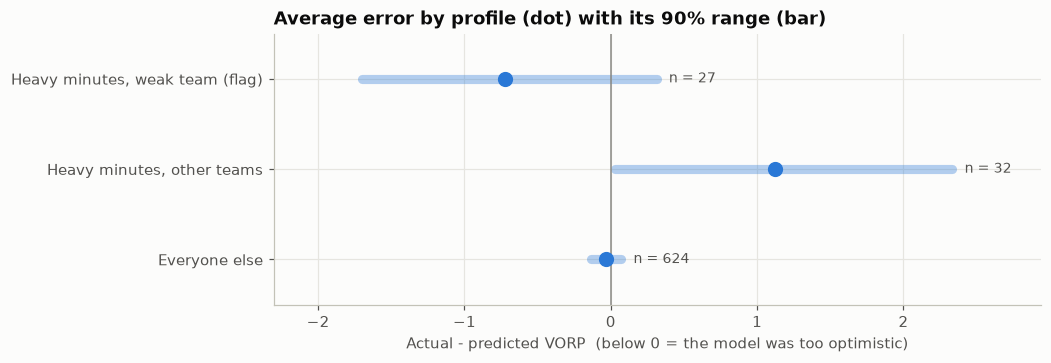

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (name, r) in enumerate(flag_table.iterrows()):
    ax.plot([r["90% range low"], r["90% range high"]], [i, i], color=BLUE, linewidth=6, alpha=0.35,
            solid_capstyle="round")
    ax.scatter(r["avg error (actual - predicted)"], i, s=80, color=BLUE, zorder=3)
    ax.annotate(f"n = {int(r['players'])}", (r["90% range high"], i), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set_yticks(range(len(flag_table)), flag_table.index)
ax.set_ylim(len(flag_table) - 0.5, -0.5)
ax.margins(x=0.15)
ax.set(title="Average error by profile (dot) with its 90% range (bar)",
       xlabel="Actual - predicted VORP  (below 0 = the model was too optimistic)")
plt.show()

**What to look for:** whether the flagged group's bar sits clearly left of 0
(the model was too optimistic for them) and how wide it is. With a small group,
a wide bar is the honest answer: the warning should say "historically over-
predicted by about X, but with only N cases".

In [5]:
cols = ["player_name", "draft_year", "pick", "mpg", "usg_pct", "ts_add36", "team_net_window", m.TARGET]
(dev[flagged(dev)].assign(predicted=current_oof[flagged(dev)])
    [cols + ["predicted"]].sort_values("predicted", ascending=False).round(2))

,player_name,draft_year,pick,mpg,usg_pct,ts_add36,team_net_window,target_vorp,predicted
55,Shane Battier,2001,6,39.32,-0.02,-0.02,-8.63,5.1,7.36
439,Blake Griffin,2009,1,36.32,0.05,-0.56,-6.16,8.7,6.90
650,Michael Carter-Williams,2013,11,36.80,0.03,-1.56,-8.21,0.2,6.62
52,Pau Gasol,2001,3,34.72,0.01,0.08,-8.63,5.7,5.77
191,Emeka Okafor,2004,2,36.72,0.01,-1.47,-5.59,3.0,5.36
393,Russell Westbrook,2008,4,28.28,0.04,-2.38,-10.26,7.4,5.31
589,Anthony Davis,2012,1,30.50,0.01,0.38,-7.29,9.9,5.03
100,Jay Williams,2002,2,31.40,0.00,-1.83,-5.40,0.0,4.87
489,John Wall,2010,1,38.13,0.02,-1.15,-8.50,6.0,4.59
444,Jonny Flynn,2009,6,29.24,0.04,-0.76,-11.06,-0.3,4.56


**What to look for:** who is in the group. A mix of busts and real players would
explain why no feature could learn the pattern; the flag is still useful as
context for whoever reads a projection.

## 3. Decision

**Features: rejected.** Neither `young_minutes_share` nor `ts_add36` (nor both)
beats the current model: each wins only 9-11 of 25 splits and the mean RMSE goes
slightly up. They stay in the data, documented, but not in the model.

**Warning flag: kept**, as context on the player cards (`src/projection.py`:
`minutes_profile`, `profile_history`, `profile_warning`). The pattern is real
but small and noisy:

- heavy minutes on a weak team: the model was too optimistic by ~0.7 VORP on
  average, but the 90% range still includes 0 (27 players)
- heavy minutes on other teams: the model was too *cautious* by ~1.1 VORP
  (32 players), the mirror image

So the minutes signal is worth more when it comes from a decent team and less
when it comes from a bad one. With ~60 such players in history the model can't
learn that reliably, which is exactly why it goes on the card as a human-readable
warning instead of into the model. The flagged list is a genuine mix of busts
(Carter-Williams, Jonny Flynn, Jay Williams, Dajuan Wagner) and stars (Durant,
Anthony Davis, Westbrook, Blake Griffin): heavy minutes on a bad team are a
yellow light, not a verdict.

In [6]:
import projection as pj
history = pj.profile_history(dev, current_oof)
example = dev[dev["player_name"] == "Michael Carter-Williams"]
print(pj.profile_warning(pj.minutes_profile(example).iloc[0], history))
history.round(2)

Warning - heavy minutes, weak team: historically the model was too optimistic for this profile by 0.7 VORP on average (90% range -1.7 to +0.3, 27 players)


,players,avg_error,low,high
"Heavy minutes, weak team",27.0,-0.72,-1.70,0.31
"Heavy minutes, other team",32.0,1.12,-0.01,2.31
